### imports et envoi du fichier

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

envoi = files.upload()          # choisir dataset_pzem.csv
nom = list(envoi.keys())[0]
print("Fichier reçu :", nom)

Saving dataset_pzem.csv to dataset_pzem (1).csv
Fichier reçu : dataset_pzem (1).csv


### premier coup d'œil aux données

In [ ]:
df = pd.read_csv(nom)

print("Taille :", df.shape)
print("\nLignes par état :")
print(df["etat"].value_counts())
print("\nValeurs manquantes :", df.isna().sum().sum())
df.head()

Taille : (4095, 18)

Lignes par état :
etat
balourd        1765
normal         1761
obstruction     569
Name: count, dtype: int64

Valeurs manquantes : 0


,horodatage,etat,t_s,moteur,pp_x,pp_y,pp_z,rms_x,rms_y,rms_z,g_x,g_y,g_z,courant_a,tension_v,puissance_w,facteur_p,temp_c
0,2026-11-24 16:06:18,normal,33,ON,0.57,0.50,0.61,0.182,0.153,0.161,8.03,4.94,1.02,0.136,240.2,21.8,0.67,29.1
1,2026-11-24 16:06:18,normal,34,ON,0.69,0.57,0.46,0.159,0.164,0.118,8.08,4.92,1.14,0.136,240.2,21.8,0.67,29.1
2,2026-11-24 16:06:19,normal,35,ON,0.73,0.46,0.54,0.175,0.147,0.161,8.08,4.94,1.07,0.135,240.2,21.7,0.67,29.1
3,2026-11-24 16:06:19,normal,36,ON,0.65,0.46,0.46,0.179,0.152,0.123,8.04,4.93,1.01,0.135,240.2,21.7,0.67,29.1
4,2026-11-24 16:06:22,normal,37,ON,0.69,0.50,0.61,0.176,0.149,0.140,8.11,4.95,1.11,0.135,240.2,21.7,0.67,29.1


### variables corrigées de la tension

In [ ]:
# Puissance et courant ramenés à la tension : comparables entre 240 V et 249 V
df["p_u2"] = df["puissance_w"] / df["tension_v"]**2 * 1000   # "conductance" en mS
df["i_u"]  = df["courant_a"]  / df["tension_v"]   * 1000     # en mA/V

etats   = ["normal", "balourd", "obstruction"]
couleur = {"normal": "tab:green", "balourd": "tab:orange", "obstruction": "tab:red"}

print(df.groupby("etat")[["tension_v", "puissance_w", "p_u2", "i_u", "facteur_p"]].mean().round(3))

             tension_v  puissance_w   p_u2    i_u  facteur_p
etat                                                        
balourd        242.030       21.767  0.372  0.539      0.689
normal         240.737       21.529  0.371  0.542      0.687
obstruction    249.093       30.683  0.495  0.616      0.803


### boîtes à moustaches par état

/tmp/ipykernel_1671/507433760.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(donnees, labels=etats, patch_artist=True, showfliers=False)
/tmp/ipykernel_1671/507433760.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(donnees, labels=etats, patch_artist=True, showfliers=False)
/tmp/ipykernel_1671/507433760.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(donnees, labels=etats, patch_artist=True, showfliers=False)
/tmp/ipykernel_1671/507433760.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotl

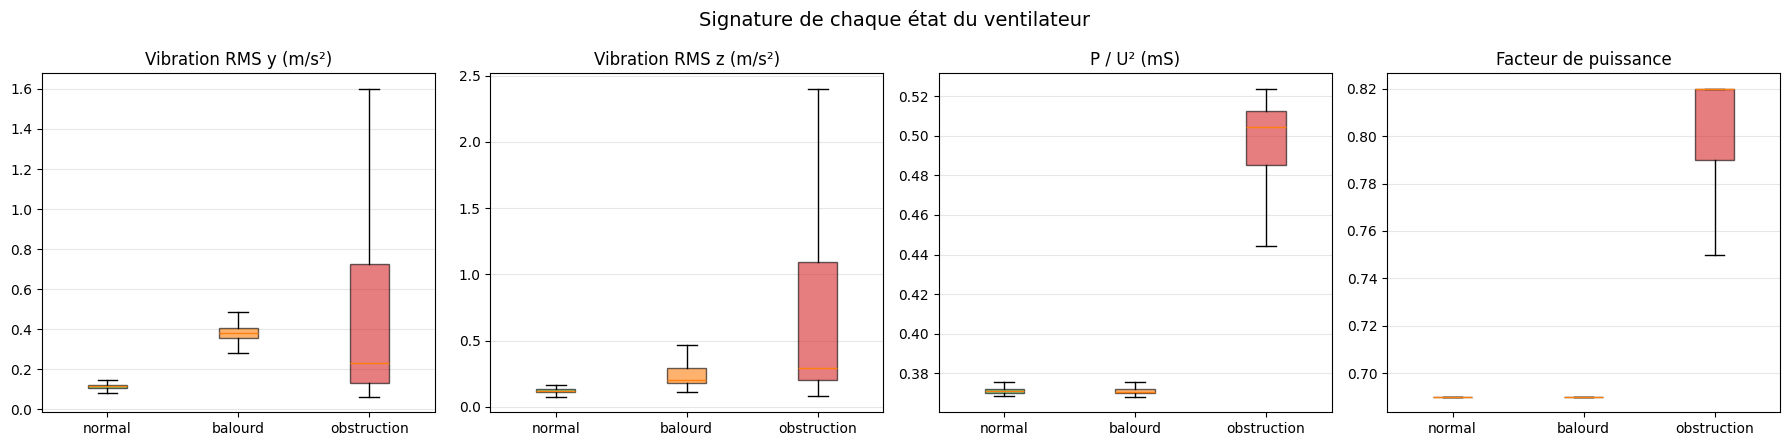

In [ ]:
variables = {
    "rms_y":     "Vibration RMS y (m/s²)",
    "rms_z":     "Vibration RMS z (m/s²)",
    "p_u2":      "P / U² (mS)",
    "facteur_p": "Facteur de puissance",
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (col, titre) in zip(axes, variables.items()):
    donnees = [df.loc[df["etat"] == e, col] for e in etats]
    bp = ax.boxplot(donnees, labels=etats, patch_artist=True, showfliers=False)
    for patch, e in zip(bp["boxes"], etats):
        patch.set_facecolor(couleur[e])
        patch.set_alpha(0.6)
    ax.set_title(titre)
    ax.grid(axis="y", alpha=0.3)
plt.suptitle("Signature de chaque état du ventilateur", fontsize=14)
plt.tight_layout()
plt.show()

### séparer l'entraînement et le test, par blocs de temps

In [ ]:
FEATURES = ["rms_x", "rms_y", "rms_z",
            "pp_x", "pp_y", "pp_z",
            "facteur_p"]

# Les 11 premières secondes de l'obstruction : plaque pas encore posée (moteur sain)
df = df[~((df["etat"] == "obstruction") & (df["t_s"] <= 43))]

df["horodatage"] = pd.to_datetime(df["horodatage"])
df = df.sort_values(["etat", "horodatage", "t_s"]).reset_index(drop=True)

TRAIN_FRAC = 0.8   # 80 % début de session -> entraînement
MARGE = 30         # 30 lignes (~30 s) écartées entre les deux

morceaux_train, morceaux_test = [], []
for e in etats:
    bloc = df[df["etat"] == e]
    coupe = int(len(bloc) * TRAIN_FRAC)
    morceaux_train.append(bloc.iloc[:coupe])
    morceaux_test.append(bloc.iloc[coupe + MARGE:])

train = pd.concat(morceaux_train)
test  = pd.concat(morceaux_test)

X_train, y_train = train[FEATURES], train["etat"]
X_test,  y_test  = test[FEATURES],  test["etat"]

print("Entraînement :", X_train.shape, y_train.value_counts().to_dict())
print("Test         :", X_test.shape,  y_test.value_counts().to_dict())

Entraînement : (3266, 7) {'balourd': 1412, 'normal': 1408, 'obstruction': 446}
Test         : (728, 7) {'normal': 323, 'balourd': 323, 'obstruction': 82}


### entraîner le classifieur

              precision    recall  f1-score   support

     balourd      1.000     1.000     1.000       323
      normal      1.000     1.000     1.000       323
 obstruction      1.000     1.000     1.000        82

    accuracy                          1.000       728
   macro avg      1.000     1.000     1.000       728
weighted avg      1.000     1.000     1.000       728



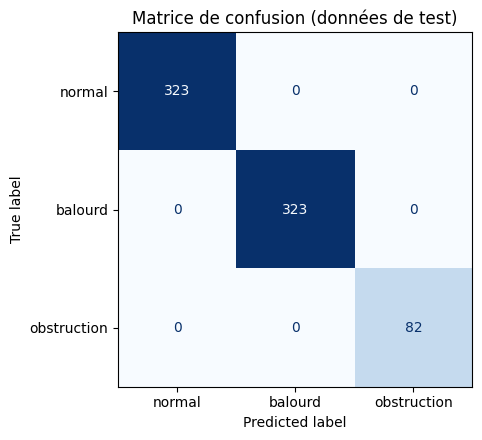

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

clf = RandomForestClassifier(
    n_estimators=200,         # 200 arbres qui votent
    max_depth=8,              # arbres pas trop profonds : évite d'apprendre par cœur
    class_weight="balanced",  # compense les 455 obstructions face aux ~1400 autres
    random_state=42,          # résultats reproductibles
    n_jobs=-1,
)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=etats,
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Matrice de confusion (données de test)")
plt.tight_layout()
plt.show()

### importance des variables

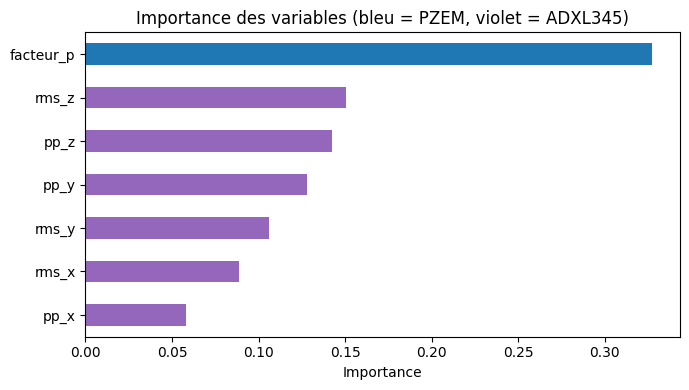

facteur_p    0.327
rms_z        0.150
pp_z         0.142
pp_y         0.128
rms_y        0.106
rms_x        0.089
pp_x         0.058
dtype: float64


In [ ]:
importances = pd.Series(clf.feature_importances_, index=FEATURES).sort_values()

couleurs = ["tab:blue" if f in ["facteur_p", "p_u2", "i_u"] else "tab:purple"
            for f in importances.index]
fig, ax = plt.subplots(figsize=(7, 4))
importances.plot.barh(ax=ax, color=couleurs)
ax.set_title("Importance des variables (bleu = PZEM, violet = ADXL345)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()
print(importances.sort_values(ascending=False).round(3))

### le modèle avec un seul type de capteur

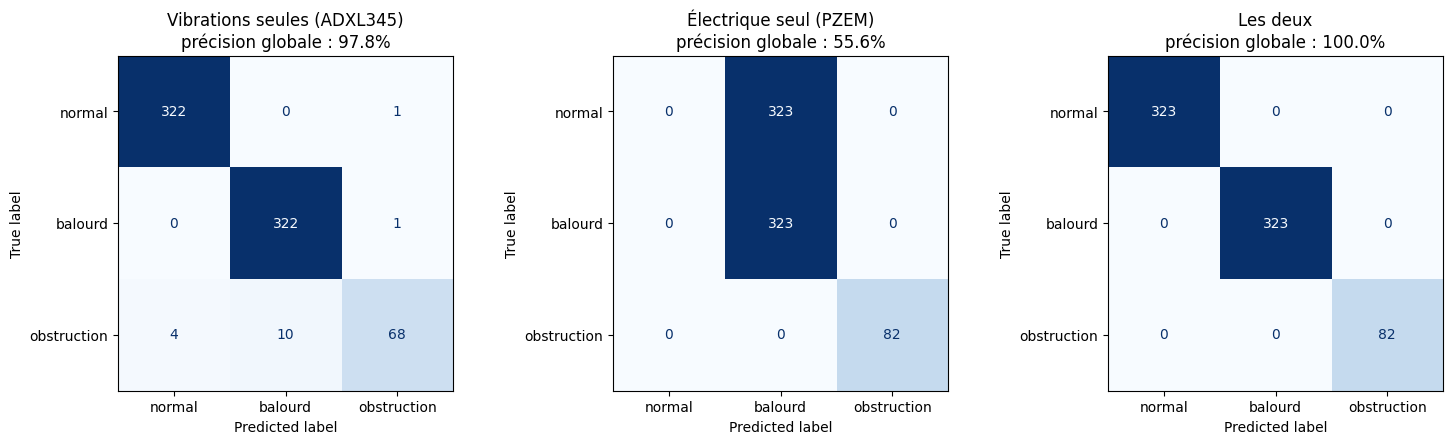

In [ ]:
from sklearn.metrics import accuracy_score

groupes = {
    "Vibrations seules (ADXL345)": ["rms_x", "rms_y", "rms_z", "pp_x", "pp_y", "pp_z"],
    "Électrique seul (PZEM)":      ["facteur_p"],
    "Les deux":                    FEATURES,
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nom_g, cols) in zip(axes, groupes.items()):
    m = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced",
                               random_state=42, n_jobs=-1).fit(X_train[cols], y_train)
    p = m.predict(X_test[cols])
    ConfusionMatrixDisplay.from_predictions(y_test, p, labels=etats, cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{nom_g}\nprécision globale : {accuracy_score(y_test, p):.1%}")
plt.tight_layout()
plt.show()

### le détecteur d'anomalies (entraîné sur le normal seul)

Seuil d'anomalie : -0.134

Part des lignes détectées comme anomalies :
etat
balourd        1.000
normal         0.000
obstruction    0.439
dtype: float64


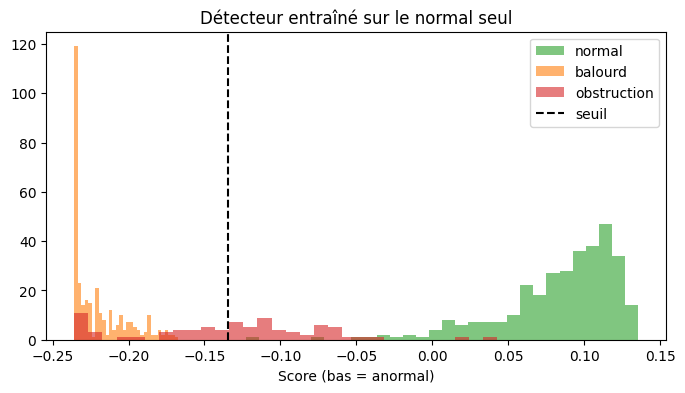

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_normal = X_train[y_train == "normal"]          # UNIQUEMENT du sain

detecteur = make_pipeline(StandardScaler(),
                          IsolationForest(n_estimators=300, random_state=42))
detecteur.fit(X_normal)

SEUIL = np.quantile(detecteur.decision_function(X_normal), 0.01)
print("Seuil d'anomalie :", round(SEUIL, 3))

score = detecteur.decision_function(X_test)
anomalie = score < SEUIL
print("\nPart des lignes détectées comme anomalies :")
print(pd.Series(anomalie, index=y_test.index).groupby(y_test).mean().round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for e in etats:
    ax.hist(score[y_test == e], bins=30, alpha=0.6, color=couleur[e], label=e)
ax.axvline(SEUIL, color="black", linestyle="--", label="seuil")
ax.set_xlabel("Score (bas = anormal)")
ax.set_title("Détecteur entraîné sur le normal seul")
ax.legend()
plt.show()

### le piège du secteur, en vrai

In [ ]:
sain_soir = pd.DataFrame([
    dict(rms_x=0.066, rms_y=0.096, rms_z=0.081, pp_x=0.27, pp_y=0.38, pp_z=0.42,
         facteur_p=0.67, p_u2=23.7/248.7**2*1000, i_u=0.141/248.7*1000),
    dict(rms_x=0.050, rms_y=0.125, rms_z=0.103, pp_x=0.19, pp_y=0.46, pp_z=0.31,
         facteur_p=0.67, p_u2=23.6/248.4**2*1000, i_u=0.141/248.4*1000),
])[FEATURES]

print("Score :", detecteur.decision_function(sain_soir).round(3), "| seuil :", round(SEUIL, 3))
print("Anomalie ?", detecteur.decision_function(sain_soir) < SEUIL)
print("Classifieur dit :", clf.predict(sain_soir))

Score : [-0.148 -0.125] | seuil : -0.134
Anomalie ? [ True False]
Classifieur dit : ['normal' 'normal']


### exporter les modèles

In [ ]:
import joblib, sklearn

# Modèles finaux : réentraînés sur TOUTES les données (train + test)
X_all, y_all = df[FEATURES], df["etat"]

clf_final = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced",
                                   random_state=42, n_jobs=-1).fit(X_all, y_all)

X_all_normal = X_all[y_all == "normal"]
det_final = make_pipeline(StandardScaler(),
                          IsolationForest(n_estimators=300, random_state=42)).fit(X_all_normal)
seuil_final = float(np.quantile(det_final.decision_function(X_all_normal), 0.01))

paquet = {
    "classifieur":     clf_final,
    "detecteur":       det_final,
    "seuil":           seuil_final,
    "features":        FEATURES,
    "classes":         list(clf_final.classes_),
    "sklearn_version": sklearn.__version__,
}
joblib.dump(paquet, "predictmotor_modele.joblib")
print("Exporté | scikit-learn", sklearn.__version__, "| seuil", round(seuil_final, 3))

# Vérification : on recharge le fichier et on refait le test du moteur sain à la maison
p = joblib.load("predictmotor_modele.joblib")
print("Moteur sain maison ->", p["classifieur"].predict(sain_soir[p["features"]]))

files.download("predictmotor_modele.joblib")

Exporté | scikit-learn 1.6.1 | seuil -0.143
Moteur sain maison -> ['normal' 'normal']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Précision sur le test : 100.0%
Moteur sain maison   -> ['normal' 'normal']

|--- facteur_p <= 0.72
|   |--- pp_y <= 0.73
|   |   |--- class: normal
|   |--- pp_y >  0.73
|   |   |--- class: balourd
|--- facteur_p >  0.72
|   |--- class: obstruction



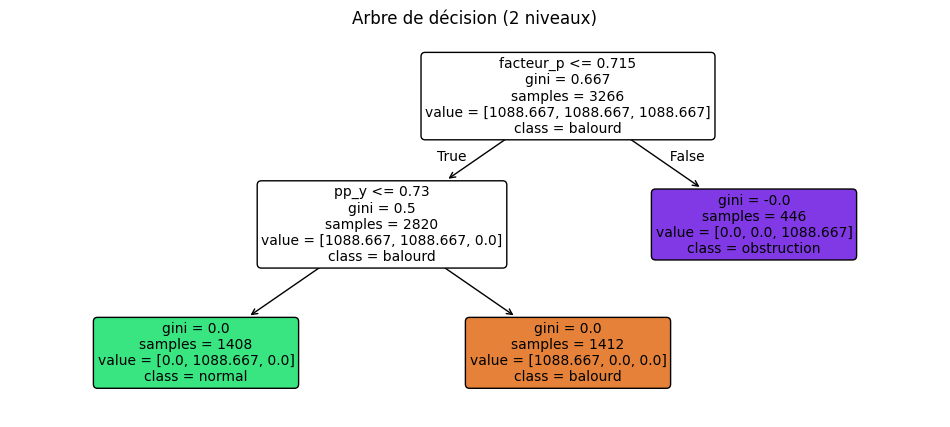

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

arbre = DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=42)
arbre.fit(X_train, y_train)

print("Précision sur le test :", f"{accuracy_score(y_test, arbre.predict(X_test)):.1%}")
print("Moteur sain maison   ->", arbre.predict(sain_soir[FEATURES]))
print()
print(export_text(arbre, feature_names=FEATURES))

plt.figure(figsize=(12, 5))
plot_tree(arbre, feature_names=FEATURES, class_names=list(arbre.classes_),
          filled=True, rounded=True, fontsize=10)
plt.title("Arbre de décision (2 niveaux)")
plt.show()

In [ ]:
from sklearn.metrics import f1_score

K, MARGE = 5, 30
cv = df.copy()
cv["pos"] = cv.groupby("etat").cumcount()                       # position dans la session
cv["bloc"] = (cv["pos"] * K // cv.groupby("etat")["pos"].transform("size")).clip(upper=K-1)

modeles = {
    "Forêt aléatoire":   lambda: RandomForestClassifier(n_estimators=200, max_depth=8,
                                     class_weight="balanced", random_state=42, n_jobs=-1),
    "Arbre (2 niveaux)": lambda: DecisionTreeClassifier(max_depth=2, class_weight="balanced",
                                     random_state=42),
}

resultats = []
for k in range(K):
    test_k = cv[cv["bloc"] == k]
    garde = pd.Series(True, index=cv.index)
    for e in etats:                                              # bloc testé + marge exclus
        t = test_k[test_k["etat"] == e]
        garde &= ~((cv["etat"] == e) & cv["pos"].between(t["pos"].min() - MARGE,
                                                         t["pos"].max() + MARGE))
    train_k = cv[garde]
    for nom, fabrique in modeles.items():
        m = fabrique().fit(train_k[FEATURES], train_k["etat"])
        p = m.predict(test_k[FEATURES])
        resultats.append({"pli": k + 1, "modèle": nom,
                          "précision": accuracy_score(test_k["etat"], p),
                          "f1": f1_score(test_k["etat"], p, average="macro"),
                          "erreurs": int((p != test_k["etat"]).sum()),
                          "lignes test": len(test_k)})

res = pd.DataFrame(resultats)
print(res.round(3).to_string(index=False))
print("\nMoyenne ± écart-type :")
print(res.groupby("modèle")[["précision", "f1"]].agg(["mean", "std"]).round(3))

 pli            modèle  précision    f1  erreurs  lignes test
   1   Forêt aléatoire      0.999 0.999        1          818
   1 Arbre (2 niveaux)      0.999 0.999        1          818
   2   Forêt aléatoire      0.998 0.998        2          817
   2 Arbre (2 niveaux)      0.998 0.998        2          817
   3   Forêt aléatoire      1.000 1.000        0          816
   3 Arbre (2 niveaux)      1.000 1.000        0          816
   4   Forêt aléatoire      1.000 1.000        0          817
   4 Arbre (2 niveaux)      1.000 1.000        0          817
   5   Forêt aléatoire      1.000 1.000        0          816
   5 Arbre (2 niveaux)      1.000 1.000        0          816

Moyenne ± écart-type :
                  précision            f1       
                       mean    std   mean    std
modèle                                          
Arbre (2 niveaux)     0.999  0.001  0.999  0.001
Forêt aléatoire       0.999  0.001  0.999  0.001


In [ ]:
import time, pickle
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

familles = {
    "Régression logistique":  lambda: make_pipeline(StandardScaler(),
                                  LogisticRegression(max_iter=2000, class_weight="balanced")),
    "k plus proches voisins": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "SVM (noyau RBF)":        lambda: make_pipeline(StandardScaler(), SVC(class_weight="balanced")),
    "Naive Bayes":            lambda: GaussianNB(),
    "Arbre (2 niveaux)":      lambda: DecisionTreeClassifier(max_depth=2, class_weight="balanced",
                                                             random_state=42),
    "Forêt aléatoire":        lambda: RandomForestClassifier(n_estimators=200, max_depth=8,
                                  class_weight="balanced", random_state=42, n_jobs=1),
    "Gradient boosting":      lambda: GradientBoostingClassifier(random_state=42),
}

lignes = []
for nom, fabrique in familles.items():
    scores = []
    for k in range(K):                                   # même validation qu'à l'étape 1.9
        test_k = cv[cv["bloc"] == k]
        garde = pd.Series(True, index=cv.index)
        for e in etats:
            t = test_k[test_k["etat"] == e]
            garde &= ~((cv["etat"] == e) & cv["pos"].between(t["pos"].min() - MARGE,
                                                             t["pos"].max() + MARGE))
        train_k = cv[garde]
        m = fabrique().fit(train_k[FEATURES], train_k["etat"])
        scores.append(accuracy_score(test_k["etat"], m.predict(test_k[FEATURES])))

    m = fabrique().fit(cv[FEATURES], cv["etat"])         # modèle complet : taille et vitesse
    une_ligne = cv[FEATURES].iloc[:1]
    t0 = time.perf_counter()
    for _ in range(200):
        m.predict(une_ligne)
    lignes.append({"modèle": nom,
                   "précision moy.": np.mean(scores),
                   "écart-type": np.std(scores, ddof=1),
                   "ms / prédiction": (time.perf_counter() - t0) / 200 * 1000,
                   "taille (ko)": len(pickle.dumps(m)) / 1024,
                   "sain maison": " / ".join(m.predict(sain_soir[FEATURES]))})

comparaison = pd.DataFrame(lignes).sort_values("précision moy.", ascending=False)
print(comparaison.round(4).to_string(index=False))

                modèle  précision moy.  écart-type  ms / prédiction  taille (ko)     sain maison
k plus proches voisins          0.9998      0.0005           6.7807     324.8682 normal / normal
     Gradient boosting          0.9995      0.0011           1.7714     375.3506 normal / normal
       SVM (noyau RBF)          0.9995      0.0007           2.6812       9.9951 normal / normal
       Forêt aléatoire          0.9993      0.0011          13.2451     689.2305 normal / normal
     Arbre (2 niveaux)          0.9993      0.0011           3.9281       1.7109 normal / normal
 Régression logistique          0.9980      0.0037           2.4158       1.5918 normal / normal
           Naive Bayes          0.9572      0.0903           3.8469       1.1572 normal / normal


Erreurs brutes  : 6 / 530
Erreurs lissées : 25 / 530
Choc à t= 30 s : fausses alarmes brut=2  lissé=0
Choc à t=200 s : fausses alarmes brut=2  lissé=0
Choc à t=380 s : fausses alarmes brut=2  lissé=0
     normal -> balourd     détecté après 5 s
    balourd -> normal      détecté après 5 s
     normal -> obstruction détecté après 5 s
obstruction -> normal      détecté après 5 s
     normal -> balourd     détecté après 5 s


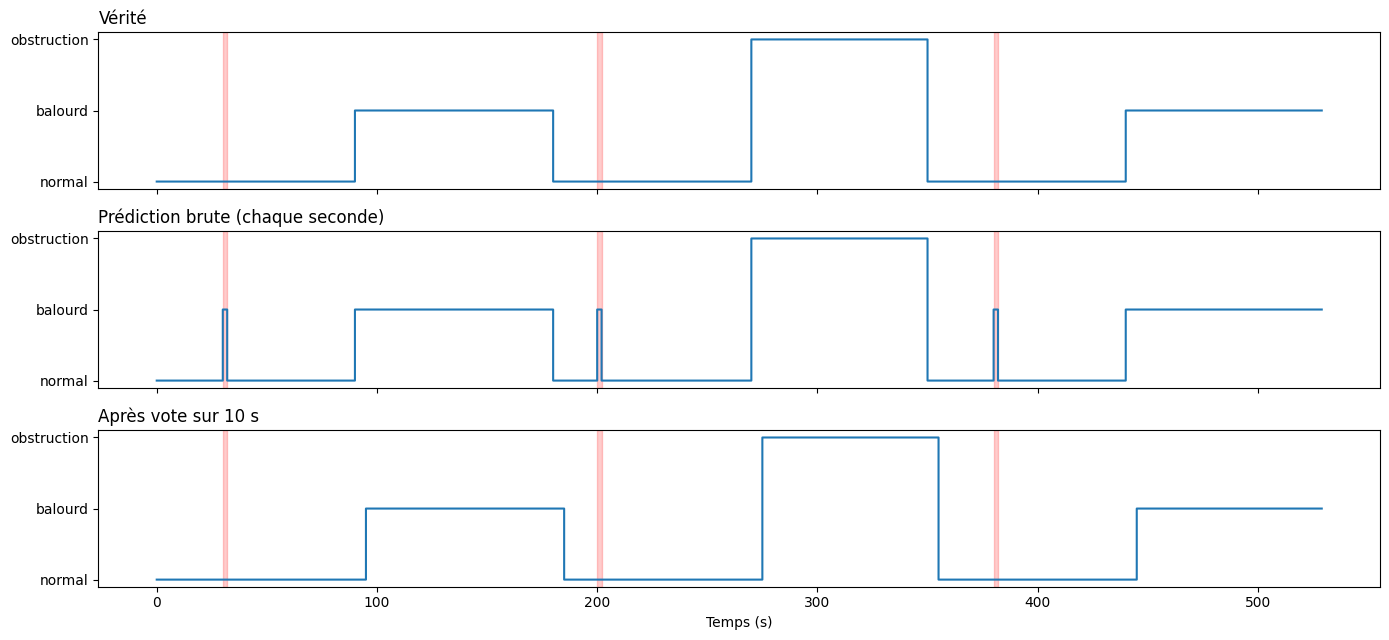

In [ ]:
from collections import deque, Counter

class Lisseur:
    """Vote majoritaire sur les N dernières prédictions (même code sur le serveur)."""
    def __init__(self, n=10):
        self.historique = deque(maxlen=n)
    def ajouter(self, etat):
        self.historique.append(etat)
        gagnant, nb = Counter(self.historique).most_common(1)[0]
        return gagnant, nb / len(self.historique)     # état retenu + part des votes

# Scénario : morceaux de la partie TEST mis bout à bout
tn, tb, to = (test[test["etat"] == e] for e in etats)
scenario = pd.concat([tn.iloc[0:90], tb.iloc[0:90], tn.iloc[90:180],
                      to.iloc[0:80], tn.iloc[180:270], tb.iloc[90:180]]).reset_index(drop=True)

# 3 chocs de 2 s pendant le normal (quelqu'un touche le banc) : vibrations x5
VIB = ["rms_x", "rms_y", "rms_z", "pp_x", "pp_y", "pp_z"]
chocs = [30, 200, 380]
for d in chocs:
    scenario.loc[d:d + 1, VIB] *= 5

scenario["brut"] = clf.predict(scenario[FEATURES])          # une prédiction par seconde
lisseur = Lisseur(10)
scenario["lisse"] = [lisseur.ajouter(p)[0] for p in scenario["brut"]]

# Bilan
print("Erreurs brutes  :", (scenario["brut"] != scenario["etat"]).sum(), "/", len(scenario))
print("Erreurs lissées :", (scenario["lisse"] != scenario["etat"]).sum(), "/", len(scenario))
for d in chocs:
    fa_brut = (scenario.loc[d:d + 1, "brut"] != scenario.loc[d:d + 1, "etat"]).sum()
    fa_lisse = (scenario.loc[d:d + 11, "lisse"] != scenario.loc[d:d + 11, "etat"]).sum()
    print(f"Choc à t={d:3d} s : fausses alarmes brut={fa_brut}  lissé={fa_lisse}")
transitions = scenario.index[scenario["etat"] != scenario["etat"].shift()][1:]
for i in transitions:
    j = i
    while j < len(scenario) and scenario.at[j, "lisse"] != scenario.at[i, "etat"]:
        j += 1
    print(f"{scenario.at[i - 1, 'etat']:>11} -> {scenario.at[i, 'etat']:<11} détecté après {j - i} s")

# Graphique
code = {e: i for i, e in enumerate(etats)}
fig, axes = plt.subplots(3, 1, figsize=(14, 6.5), sharex=True)
for ax, col, titre in zip(axes, ["etat", "brut", "lisse"],
                          ["Vérité", "Prédiction brute (chaque seconde)", "Après vote sur 10 s"]):
    ax.step(scenario.index, scenario[col].map(code), where="post")
    ax.set_yticks(range(3))
    ax.set_yticklabels(etats)
    ax.set_title(titre, loc="left")
    for d in chocs:
        ax.axvspan(d, d + 2, color="red", alpha=0.2)
axes[-1].set_xlabel("Temps (s)")
plt.tight_layout()
plt.show()